# Google Play Store Apps Analysis

### Oasis Infobyte Data Analytics Internship
**Task:** Level 2 – Task 4

**Prepared by:** Pornima Onkar Nerkar

### Project Objective
To analyse Google Play Store applications, ratings, installs, pricing, and user reviews to discover trends and insights that can help app developers make better business decisions.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px
import plotly.graph_objects as go

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

# Display dataset dimensions
print("Google Play Store Apps Dataset:", apps.shape)
print("User Reviews Dataset:", reviews.shape)

# Display first five rows of each dataset
print("\nApps Dataset:")
display(apps.head())

print("\nUser Reviews Dataset:")
display(reviews.head())

Google Play Store Apps Dataset: (10841, 13)
User Reviews Dataset: (64295, 5)

Apps Dataset:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



User Reviews Dataset:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [3]:
print("APPS DATASET INFORMATION")
print("-" * 50)

apps.info()

print("\nMissing values in Apps Dataset:")
display(apps.isnull().sum())

print("\nDuplicate rows in Apps Dataset:")
print(apps.duplicated().sum())

print("\nREVIEWS DATASET INFORMATION")
print("-" * 50)

reviews.info()

print("\nMissing values in Reviews Dataset:")
display(reviews.isnull().sum())

print("\nDuplicate rows in Reviews Dataset:")
print(reviews.duplicated().sum())

APPS DATASET INFORMATION
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 2.2 MB

Missing values in Apps Dataset:


App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


Duplicate rows in Apps Dataset:
483

REVIEWS DATASET INFORMATION
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  str    
 1   Translated_Review       37427 non-null  str    
 2   Sentiment               37432 non-null  str    
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), str(3)
memory usage: 8.3 MB

Missing values in Reviews Dataset:


App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


Duplicate rows in Reviews Dataset:
33616


In [4]:
print("Column names:")
print(apps.columns.tolist())

print("\nApp categories:")
print(apps['Category'].value_counts().head(15))

print("\nApp types:")
print(apps['Type'].value_counts(dropna=False))

print("\nInstall values:")
print(apps['Installs'].value_counts().head(10))

print("\nPrice values:")
print(apps['Price'].value_counts().head(10))

print("\nApp sizes:")
print(apps['Size'].value_counts().head(10))

Column names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

App categories:
Category
FAMILY                1972
GAME                  1144
TOOLS                  843
MEDICAL                463
BUSINESS               460
PRODUCTIVITY           424
PERSONALIZATION        392
COMMUNICATION          387
SPORTS                 384
LIFESTYLE              382
FINANCE                366
HEALTH_AND_FITNESS     341
PHOTOGRAPHY            335
SOCIAL                 295
NEWS_AND_MAGAZINES     283
Name: count, dtype: int64

App types:
Type
Free    10039
Paid      800
NaN         1
0           1
Name: count, dtype: int64

Install values:
Installs
1,000,000+     1579
10,000,000+    1252
100,000+       1169
10,000+        1054
1,000+          907
5,000,000+      752
100+            719
500,000+        539
50,000+         479
5,000+          477
Name: count, dtype: int64

Price values:
Price
0    

In [5]:
# Create a copy of the original Apps dataset
apps_clean = apps.copy()

# Remove duplicate app records
apps_clean = apps_clean.drop_duplicates(subset='App', keep='last')

# Remove invalid category records
apps_clean = apps_clean[
    apps_clean['Category'].notna() &
    (apps_clean['Category'] != '1.9')
]

# Convert Rating and Reviews into numeric values
apps_clean['Rating'] = pd.to_numeric(
    apps_clean['Rating'], errors='coerce'
)

apps_clean['Reviews'] = pd.to_numeric(
    apps_clean['Reviews'], errors='coerce'
)

# Clean and convert Installs
apps_clean['Installs'] = (
    apps_clean['Installs']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.replace('+', '', regex=False)
)

apps_clean['Installs'] = pd.to_numeric(
    apps_clean['Installs'], errors='coerce'
)

# Clean and convert Price
apps_clean['Price'] = (
    apps_clean['Price']
    .astype(str)
    .str.replace('$', '', regex=False)
)

apps_clean['Price'] = pd.to_numeric(
    apps_clean['Price'], errors='coerce'
)

# Convert app Size into MB
def convert_size(size):
    size = str(size).strip()

    if size.endswith('M'):
        return float(size[:-1])
    elif size.endswith('k'):
        return float(size[:-1]) / 1024
    else:
        return np.nan

apps_clean['Size_MB'] = apps_clean['Size'].apply(convert_size)

# Remove invalid app types
apps_clean = apps_clean[
    apps_clean['Type'].isin(['Free', 'Paid'])
]

print("Apps dataset cleaning completed!")
print("Original rows:", len(apps))
print("Cleaned rows:", len(apps_clean))

print("\nRemaining missing values:")
display(apps_clean.isnull().sum())

display(apps_clean.head())

Apps dataset cleaning completed!
Original rows: 10841
Cleaned rows: 9658

Remaining missing values:


App                  0
Category             0
Rating            1462
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1226
dtype: int64

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Size_MB
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,10000,Free,0.0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,19.0
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,5000000,Free,0.0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,8.7
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,50000000,Free,0.0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,25.0
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,100000,Free,0.0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,2.8
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,50000,Free,0.0,Everyone,Art & Design,"March 26, 2017",1.0,2.3 and up,5.6


In [6]:
# Create a copy of the reviews dataset
reviews_clean = reviews.copy()

# Remove duplicate review records
reviews_clean = reviews_clean.drop_duplicates()

# Remove rows without review text
reviews_clean = reviews_clean.dropna(
    subset=['Translated_Review']
)

# Remove rows without sentiment labels
reviews_clean = reviews_clean.dropna(
    subset=['Sentiment']
)

# Remove blank reviews
reviews_clean = reviews_clean[
    reviews_clean['Translated_Review'].str.strip() != ''
]

print("Reviews dataset cleaning completed!")
print("Original review rows:", len(reviews))
print("Cleaned review rows:", len(reviews_clean))

print("\nSentiment distribution:")
display(reviews_clean['Sentiment'].value_counts())

print("\nCleaned reviews preview:")
display(reviews_clean.head())

Reviews dataset cleaning completed!
Original review rows: 64295
Cleaned review rows: 29692

Sentiment distribution:


Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


Cleaned reviews preview:


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000
5,10 Best Foods for You,Best way,Positive,1.00,0.300000


Total number of app categories: 33


Category
FAMILY                1905
GAME                   926
TOOLS                  829
BUSINESS               419
MEDICAL                396
PERSONALIZATION        376
PRODUCTIVITY           374
LIFESTYLE              369
FINANCE                345
SPORTS                 327
COMMUNICATION          316
HEALTH_AND_FITNESS     287
PHOTOGRAPHY            281
NEWS_AND_MAGAZINES     254
SOCIAL                 239
Name: count, dtype: int64

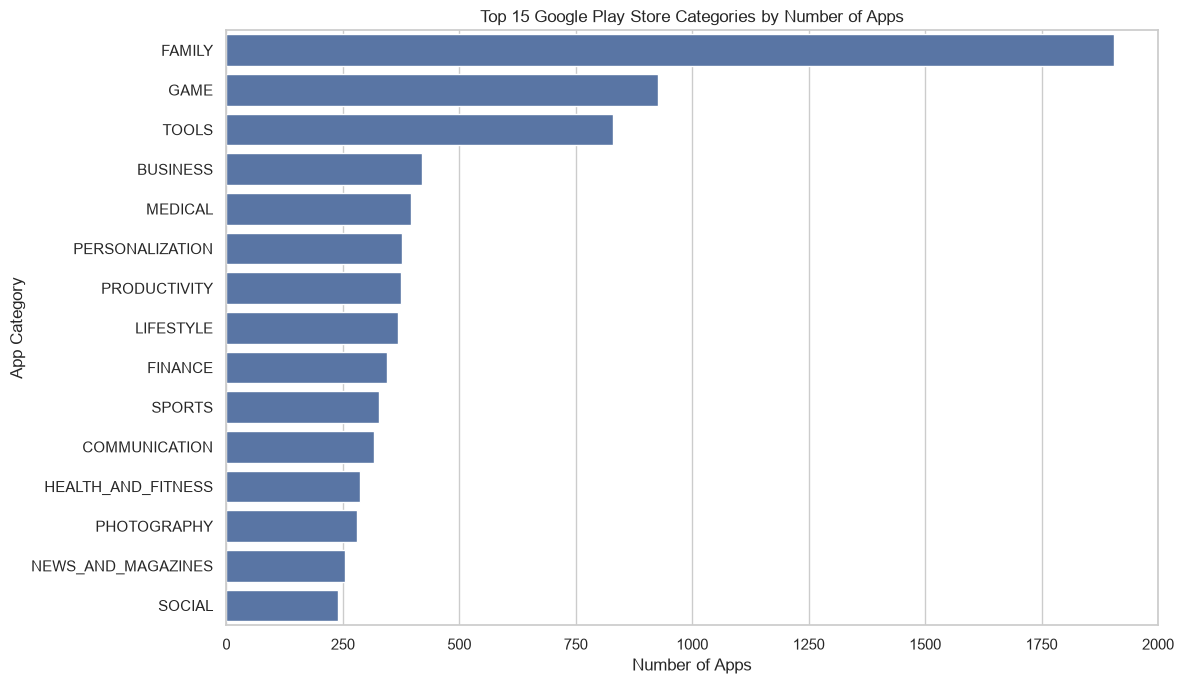

In [7]:
# Count apps in each category
category_counts = apps_clean['Category'].value_counts()

print("Total number of app categories:", len(category_counts))

# Display top 15 categories
display(category_counts.head(15))

# Create category distribution chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_counts.head(15).values,
    y=category_counts.head(15).index
)

plt.title("Top 15 Google Play Store Categories by Number of Apps")
plt.xlabel("Number of Apps")
plt.ylabel("App Category")
plt.tight_layout()
plt.show()

Average App Rating by Category:


Category
EVENTS                 4.44
ART_AND_DESIGN         4.36
EDUCATION              4.35
BOOKS_AND_REFERENCE    4.34
PERSONALIZATION        4.33
PARENTING              4.30
BEAUTY                 4.28
SOCIAL                 4.25
WEATHER                4.24
HEALTH_AND_FITNESS     4.24
GAME                   4.24
SHOPPING               4.23
SPORTS                 4.22
AUTO_AND_VEHICLES      4.19
FAMILY                 4.19
PRODUCTIVITY           4.18
COMICS                 4.18
LIBRARIES_AND_DEMO     4.18
FOOD_AND_DRINK         4.17
MEDICAL                4.17
PHOTOGRAPHY            4.16
HOUSE_AND_HOME         4.14
NEWS_AND_MAGAZINES     4.12
COMMUNICATION          4.12
FINANCE                4.12
ENTERTAINMENT          4.11
BUSINESS               4.10
LIFESTYLE              4.09
TRAVEL_AND_LOCAL       4.07
VIDEO_PLAYERS          4.04
TOOLS                  4.04
MAPS_AND_NAVIGATION    4.04
DATING                 3.98
Name: Rating, dtype: float64

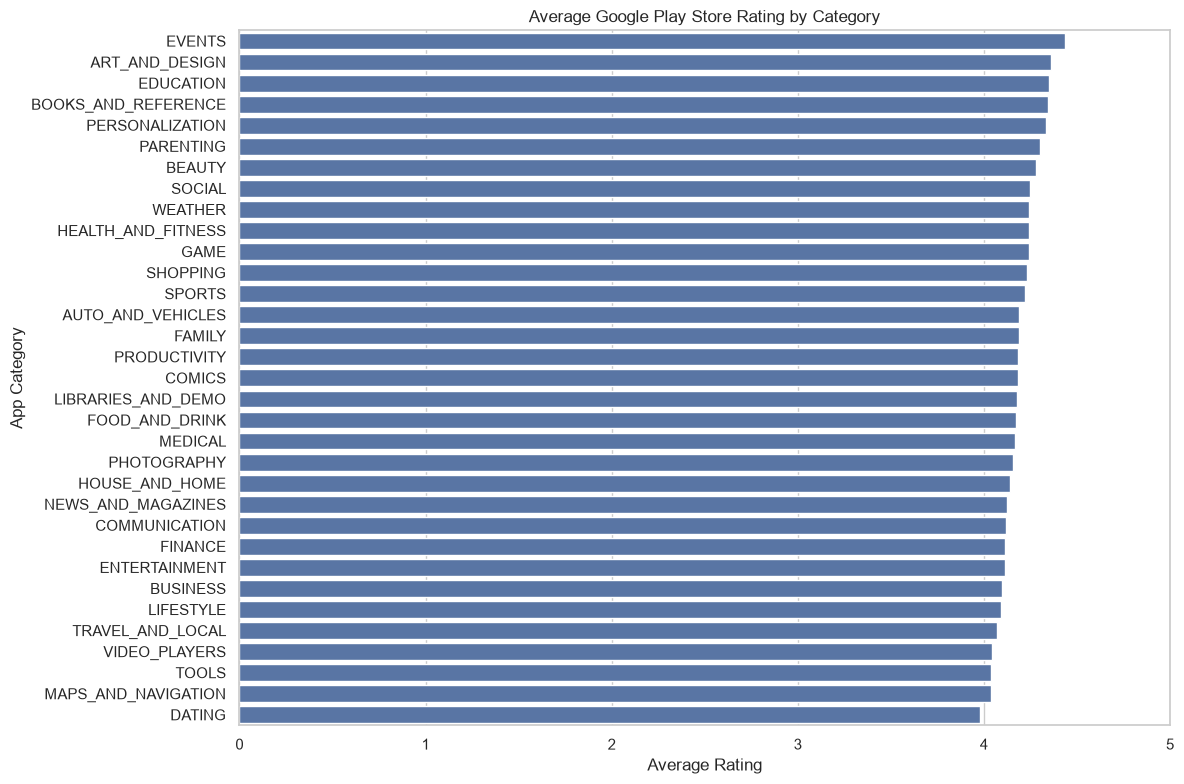

In [8]:
# Calculate average rating by category

category_ratings = (
    apps_clean.groupby('Category')['Rating']
    .mean()
    .sort_values(ascending=False)
)

print("Average App Rating by Category:")
display(category_ratings.round(2))

# Plot average ratings
plt.figure(figsize=(12, 8))

sns.barplot(
    x=category_ratings.values,
    y=category_ratings.index
)

plt.title("Average Google Play Store Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("App Category")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

Top 15 Categories by Total Installs:


Category
COMMUNICATION          11039276251
GAME                   10897924415
FAMILY                  8870642505
TOOLS                   8102771915
PRODUCTIVITY            5788091369
SOCIAL                  5487867902
PHOTOGRAPHY             4658147655
VIDEO_PLAYERS           3917002720
TRAVEL_AND_LOCAL        2894887146
NEWS_AND_MAGAZINES      2369217760
BOOKS_AND_REFERENCE     1665969576
PERSONALIZATION         1532494782
SHOPPING                1400348785
SPORTS                  1296474498
HEALTH_AND_FITNESS      1134022512
Name: Installs, dtype: int64

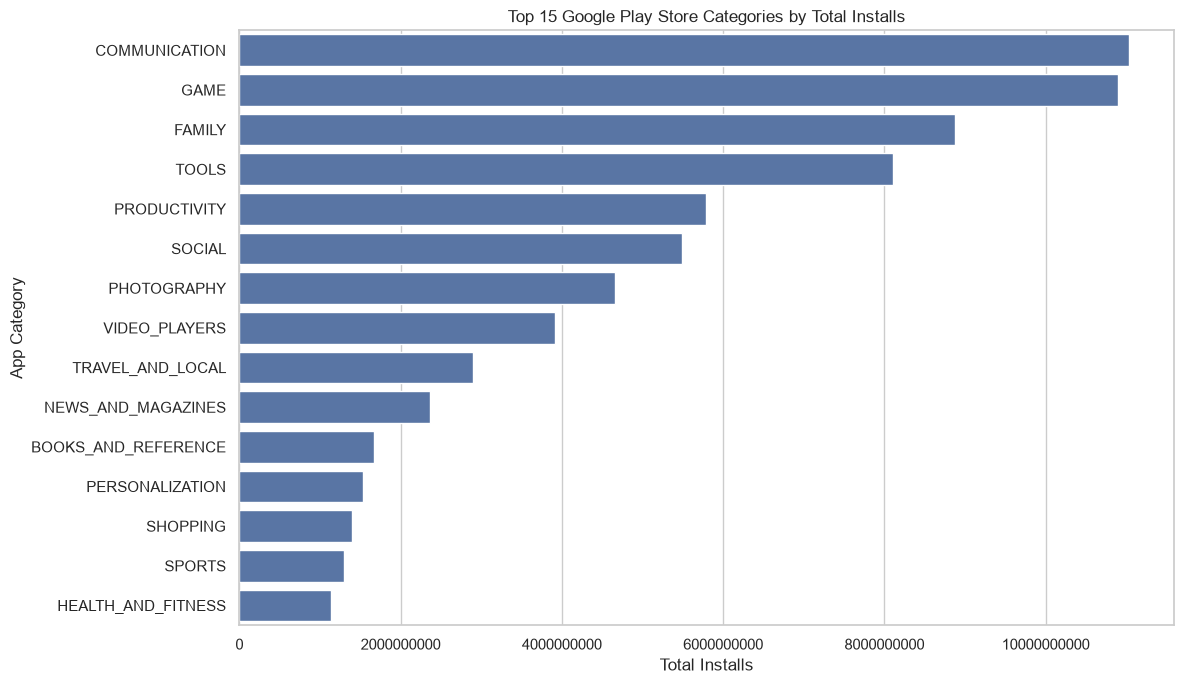

In [9]:
# Calculate total installs by category

category_installs = (
    apps_clean.groupby('Category')['Installs']
    .sum()
    .sort_values(ascending=False)
)

print("Top 15 Categories by Total Installs:")
display(category_installs.head(15))

# Create bar chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_installs.head(15).values,
    y=category_installs.head(15).index
)

plt.title("Top 15 Google Play Store Categories by Total Installs")
plt.xlabel("Total Installs")
plt.ylabel("App Category")
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

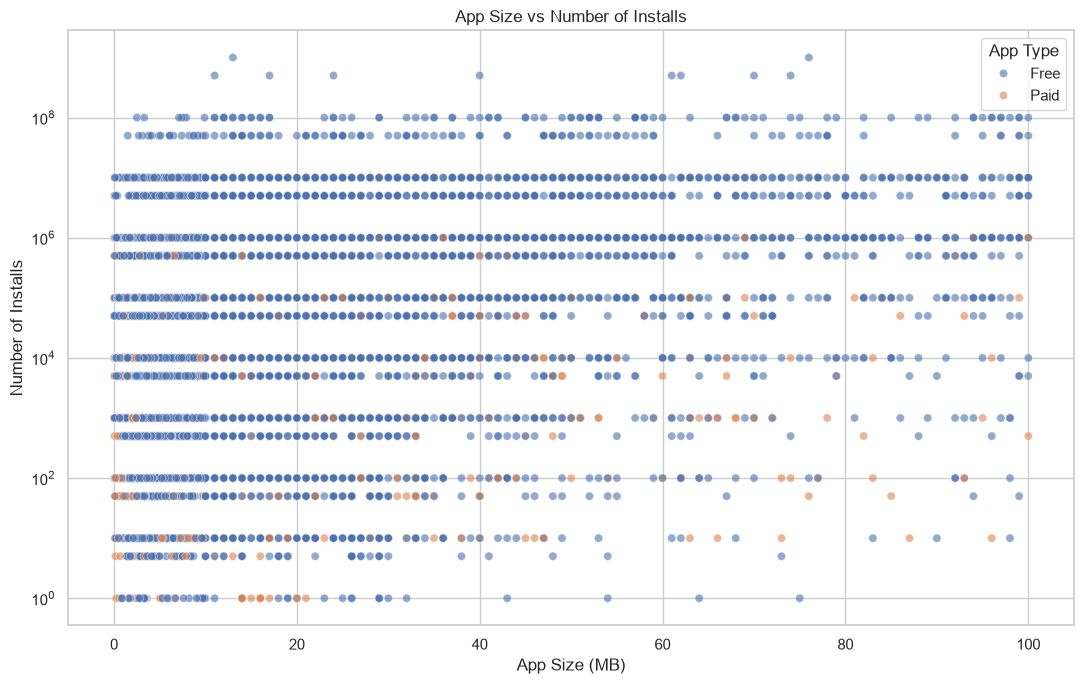

Correlation between App Size and Installs: 0.134


In [10]:
# Create a sample for a clearer scatter plot
size_install_data = apps_clean.dropna(
    subset=['Size_MB', 'Installs']
).copy()

plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=size_install_data,
    x='Size_MB',
    y='Installs',
    hue='Type',
    alpha=0.6
)

plt.title("App Size vs Number of Installs")
plt.xlabel("App Size (MB)")
plt.ylabel("Number of Installs")
plt.yscale('log')
plt.legend(title="App Type")
plt.tight_layout()
plt.show()

# Calculate correlation
correlation = size_install_data[
    ['Size_MB', 'Installs']
].corr().iloc[0, 1]

print("Correlation between App Size and Installs:", round(correlation, 3))

Free vs Paid Apps:


Type
Free    8904
Paid     754
Name: count, dtype: int64

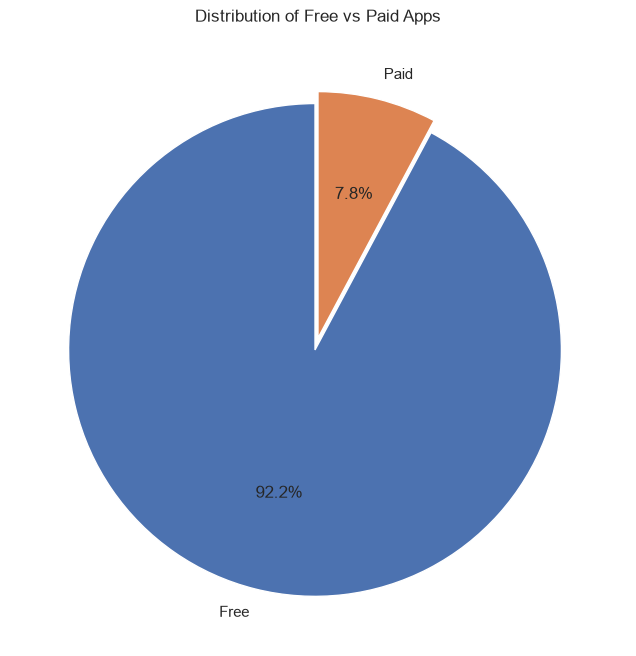


Average price by app type:


Type
Free     0.00
Paid    14.06
Name: Price, dtype: float64

In [11]:
# Count free and paid apps
type_counts = apps_clean['Type'].value_counts()

print("Free vs Paid Apps:")
display(type_counts)

# Create pie chart
plt.figure(figsize=(8, 8))

plt.pie(
    type_counts,
    labels=type_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    explode=(0.05, 0)
)

plt.title("Distribution of Free vs Paid Apps")
plt.show()

# Compare average price
print("\nAverage price by app type:")
display(
    apps_clean.groupby('Type')['Price'].mean().round(2)
)

Paid Apps Price Statistics:


count    754.00
mean      14.06
std       58.82
min        0.99
25%        1.49
50%        2.99
75%        4.99
max      400.00
Name: Price, dtype: float64

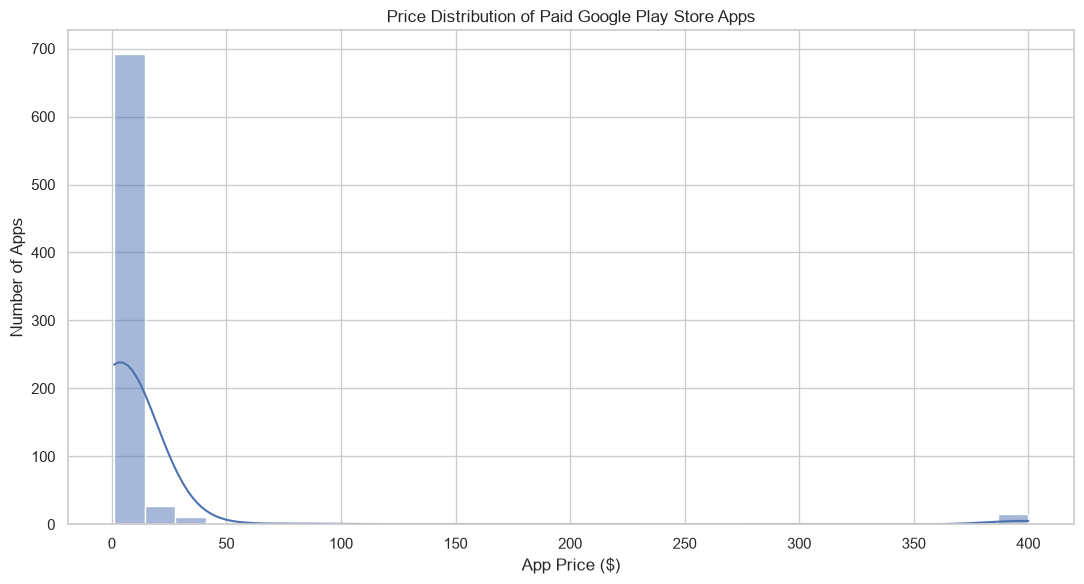


Top 10 Most Expensive Apps:


,App,Category,Price
4367,I'm Rich - Trump Edition,LIFESTYLE,400.00
9934,I'm Rich/Eu sou Rico/أنا غني/我很有錢,LIFESTYLE,399.99
4197,most expensive app (H),FAMILY,399.99
4362,💎 I'm rich,LIFESTYLE,399.99
5356,I Am Rich Premium,FINANCE,399.99
5373,I AM RICH PRO PLUS,FINANCE,399.99
5351,I am rich,LIFESTYLE,399.99
5354,I am Rich Plus,FAMILY,399.99
5369,I am Rich,FINANCE,399.99
5359,I am rich(premium),FINANCE,399.99


In [12]:
# Filter paid apps
paid_apps = apps_clean[apps_clean['Type'] == 'Paid'].copy()

print("Paid Apps Price Statistics:")
display(paid_apps['Price'].describe().round(2))

# Plot price distribution
plt.figure(figsize=(11, 6))

sns.histplot(
    paid_apps['Price'],
    bins=30,
    kde=True
)

plt.title("Price Distribution of Paid Google Play Store Apps")
plt.xlabel("App Price ($)")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()

# Display the 10 most expensive apps
print("\nTop 10 Most Expensive Apps:")
display(
    paid_apps[['App', 'Category', 'Price']]
    .sort_values('Price', ascending=False)
    .head(10)
)

Top 15 Categories by Estimated Revenue:


Category
FAMILY                 1.156808e+08
LIFESTYLE              5.758394e+07
GAME                   4.068864e+07
FINANCE                2.572668e+07
PHOTOGRAPHY            8.547768e+06
PERSONALIZATION        6.796948e+06
MEDICAL                5.956237e+06
TOOLS                  5.464821e+06
SPORTS                 4.706212e+06
PRODUCTIVITY           4.313375e+06
COMMUNICATION          4.247364e+06
WEATHER                4.181380e+06
HEALTH_AND_FITNESS     1.426069e+06
MAPS_AND_NAVIGATION    1.240789e+06
TRAVEL_AND_LOCAL       1.151504e+06
Name: Estimated_Revenue, dtype: float64

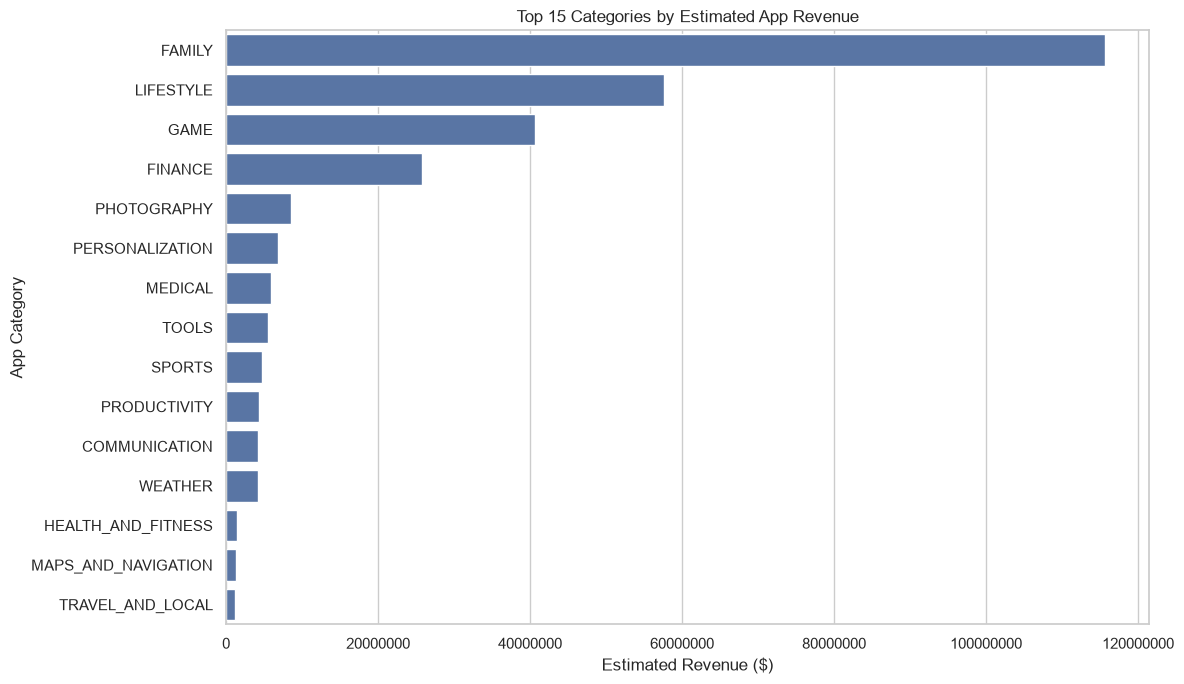

In [13]:
# Calculate estimated revenue for paid apps

paid_apps = apps_clean[apps_clean['Type'] == 'Paid'].copy()

paid_apps['Estimated_Revenue'] = (
    paid_apps['Price'] * paid_apps['Installs']
)

# Calculate estimated revenue by category
category_revenue = (
    paid_apps.groupby('Category')['Estimated_Revenue']
    .sum()
    .sort_values(ascending=False)
)

print("Top 15 Categories by Estimated Revenue:")
display(category_revenue.head(15).round(2))

# Create revenue chart
plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_revenue.head(15).values,
    y=category_revenue.head(15).index
)

plt.title("Top 15 Categories by Estimated App Revenue")
plt.xlabel("Estimated Revenue ($)")
plt.ylabel("App Category")
plt.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

User Sentiment Distribution:


Sentiment
Positive    19015
Negative     6321
Neutral      4356
Name: count, dtype: int64


Sentiment Percentages:


Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: proportion, dtype: float64

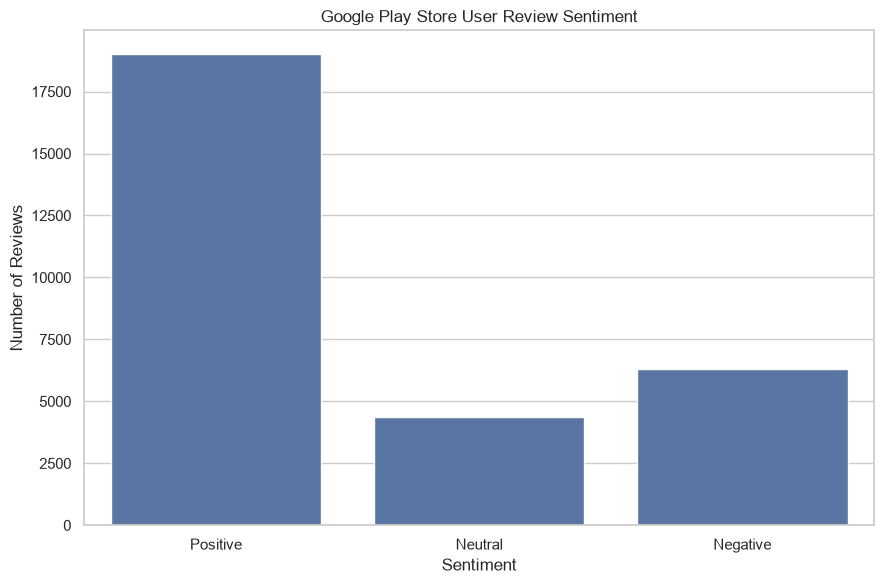

In [14]:
# Calculate sentiment distribution
sentiment_counts = reviews_clean['Sentiment'].value_counts()

print("User Sentiment Distribution:")
display(sentiment_counts)

# Calculate sentiment percentages
sentiment_percentages = (
    reviews_clean['Sentiment'].value_counts(normalize=True) * 100
)

print("\nSentiment Percentages:")
display(sentiment_percentages.round(2))

# Create sentiment chart
plt.figure(figsize=(9, 6))

sns.countplot(
    data=reviews_clean,
    x='Sentiment',
    order=['Positive', 'Neutral', 'Negative']
)

plt.title("Google Play Store User Review Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Top 10 Categories by Positive Reviews:


Sentiment,Negative,Neutral,Positive
Category,,,
GAME,1236,189,2049
FAMILY,853,288,1873
HEALTH_AND_FITNESS,178,181,1262
TOOLS,239,317,842
FINANCE,300,195,841
TRAVEL_AND_LOCAL,267,233,831
SPORTS,331,164,820
MEDICAL,179,187,790
PRODUCTIVITY,208,169,758



Top 10 Categories by Negative Reviews:


Sentiment,Negative,Neutral,Positive
Category,,,
GAME,1236,189,2049
FAMILY,853,288,1873
SPORTS,331,164,820
FINANCE,300,195,841
TRAVEL_AND_LOCAL,267,233,831
TOOLS,239,317,842
DATING,228,190,669
PRODUCTIVITY,208,169,758
SOCIAL,190,104,367


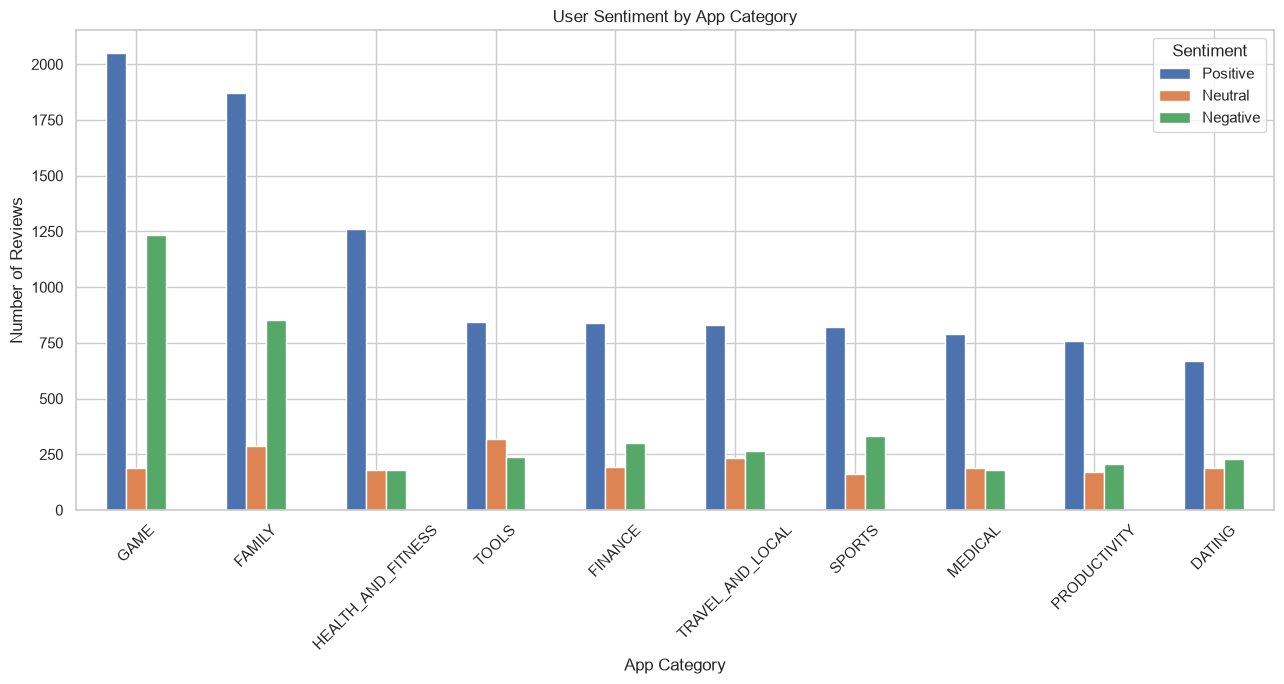

In [15]:
# Merge app categories with user reviews

reviews_with_category = reviews_clean.merge(
    apps_clean[['App', 'Category']],
    on='App',
    how='inner'
)

# Count sentiment by category
category_sentiment = pd.crosstab(
    reviews_with_category['Category'],
    reviews_with_category['Sentiment']
)

# Calculate positive and negative review counts
category_sentiment = category_sentiment.sort_values(
    by='Positive',
    ascending=False
)

print("Top 10 Categories by Positive Reviews:")
display(category_sentiment.head(10))

print("\nTop 10 Categories by Negative Reviews:")
display(
    category_sentiment.sort_values(
        by='Negative',
        ascending=False
    ).head(10)
)

# Plot sentiment by category
category_sentiment[['Positive', 'Neutral', 'Negative']].head(10).plot(
    kind='bar',
    figsize=(13, 7)
)

plt.title("User Sentiment by App Category")
plt.xlabel("App Category")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

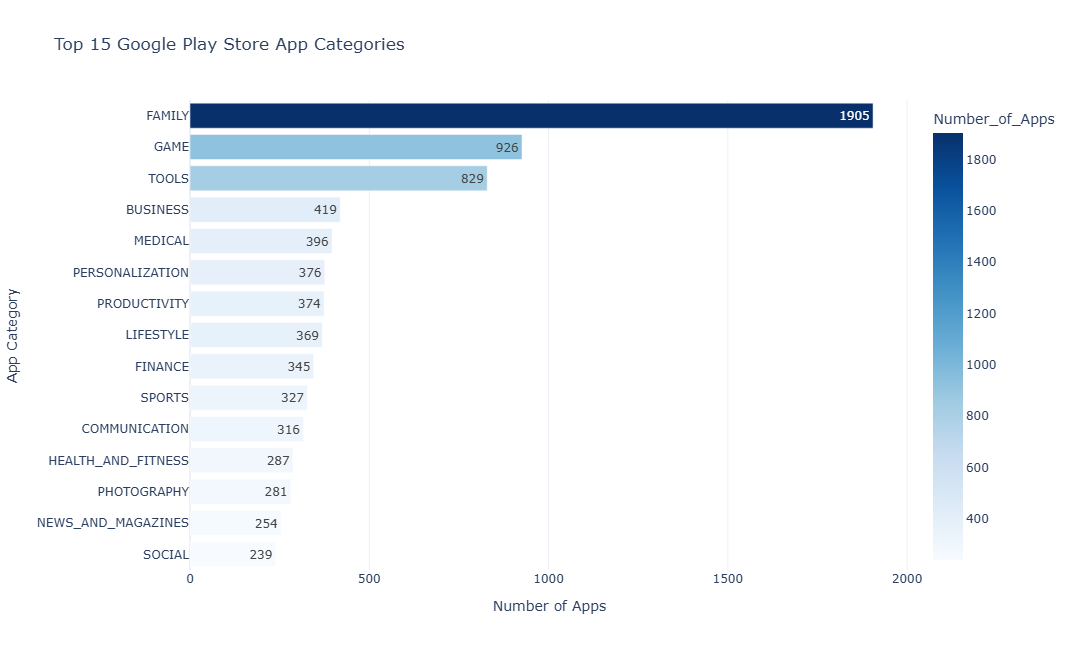

In [16]:
# Interactive Plotly chart: Top 15 App Categories

top_categories = (
    apps_clean['Category']
    .value_counts()
    .head(15)
    .reset_index()
)

top_categories.columns = ['Category', 'Number_of_Apps']

fig = px.bar(
    top_categories,
    x='Number_of_Apps',
    y='Category',
    orientation='h',
    color='Number_of_Apps',
    color_continuous_scale='Blues',
    title='Top 15 Google Play Store App Categories',
    text='Number_of_Apps'
)

fig.update_layout(
    height=650,
    yaxis={'categoryorder': 'total ascending'},
    xaxis_title='Number of Apps',
    yaxis_title='App Category',
    template='plotly_white'
)

fig.show()

In [17]:
# Calculate dashboard KPIs

total_apps = len(apps_clean)

average_rating = apps_clean['Rating'].mean()

total_installs = apps_clean['Installs'].sum()

free_app_percentage = (
    (apps_clean['Type'] == 'Free').mean() * 100
)

print("GOOGLE PLAY STORE DASHBOARD - KEY METRICS")
print("-" * 50)

print(f"Total Apps: {total_apps:,}")
print(f"Average Rating: {average_rating:.2f} / 5")
print(f"Total Installs: {total_installs:,.0f}")
print(f"Free Apps: {free_app_percentage:.2f}%")

GOOGLE PLAY STORE DASHBOARD - KEY METRICS
--------------------------------------------------
Total Apps: 9,658
Average Rating: 4.17 / 5
Total Installs: 75,284,636,427
Free Apps: 92.19%


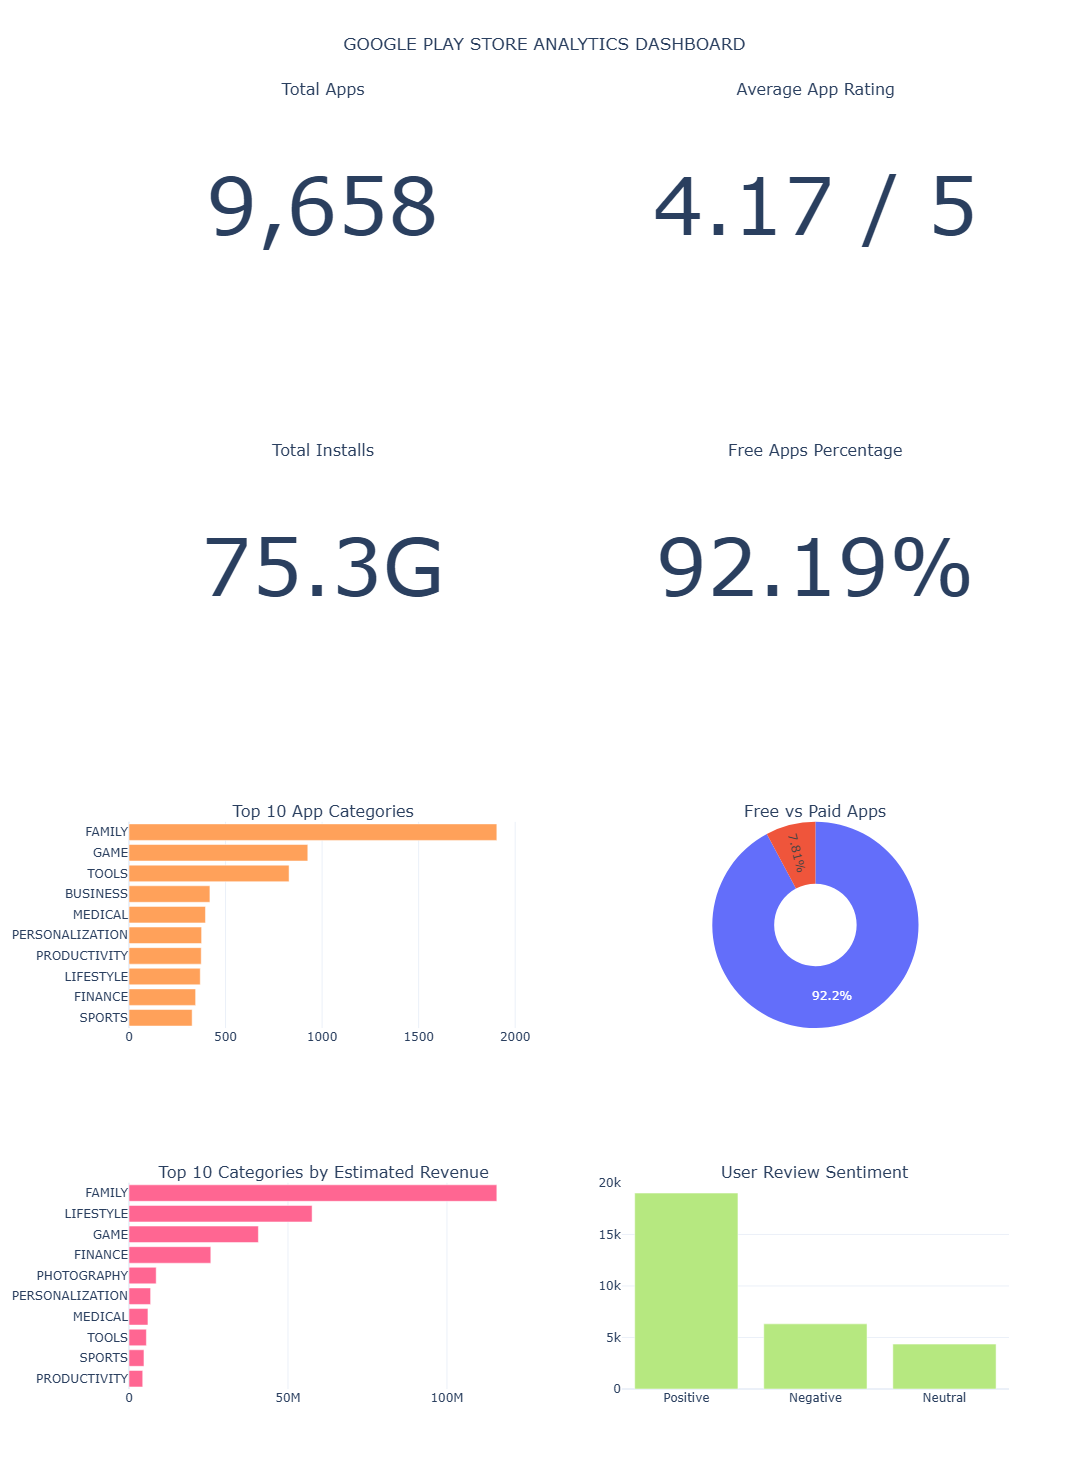

In [22]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

category_data = apps_clean['Category'].value_counts().head(10)

type_data = apps_clean['Type'].value_counts()
sentiment_data = reviews_clean['Sentiment'].value_counts()
revenue_data = category_revenue.head(10)

fig = make_subplots(
    rows=4, cols=2,
    specs=[
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "indicator"}, {"type": "indicator"}],
        [{"type": "bar"}, {"type": "pie"}],
        [{"type": "bar"}, {"type": "bar"}]
    ],
    subplot_titles=(
        "Total Apps",
        "Average App Rating",
        "Total Installs",
        "Free Apps Percentage",
        "Top 10 App Categories",
        "Free vs Paid Apps",
        "Top 10 Categories by Estimated Revenue",
        "User Review Sentiment"
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.12
)

# KPI 1
fig.add_trace(go.Indicator(
    mode="number",
    value=total_apps,
    number={"valueformat": ","}
), row=1, col=1)

# KPI 2
fig.add_trace(go.Indicator(
    mode="number",
    value=average_rating,
    number={"suffix": " / 5", "valueformat": ".2f"}
), row=1, col=2)

# KPI 3
fig.add_trace(go.Indicator(
    mode="number",
    value=total_installs,
    number={"valueformat": ".3s"}
), row=2, col=1)

# KPI 4
fig.add_trace(go.Indicator(
    mode="number",
    value=free_app_percentage,
    number={"suffix": "%", "valueformat": ".2f"}
), row=2, col=2)

# Category chart
fig.add_trace(go.Bar(
    x=category_data.values,
    y=category_data.index,
    orientation='h',
    name="Apps"
), row=3, col=1)

# Free vs Paid chart
fig.add_trace(go.Pie(
    labels=type_data.index,
    values=type_data.values,
    hole=0.4
), row=3, col=2)

# Revenue chart
fig.add_trace(go.Bar(
    x=revenue_data.values,
    y=revenue_data.index,
    orientation='h',
    name="Revenue"
), row=4, col=1)

# Sentiment chart
fig.add_trace(go.Bar(
    x=sentiment_data.index,
    y=sentiment_data.values,
    name="Reviews"
), row=4, col=2)

fig.update_layout(
    title={
        "text": "GOOGLE PLAY STORE ANALYTICS DASHBOARD",
        "x": 0.5
    },
    height=1450,
    width=1200,
    template="plotly_white",
    showlegend=False
)

fig.update_yaxes(autorange="reversed", row=3, col=1)
fig.update_yaxes(autorange="reversed", row=4, col=1)

fig.show()

In [23]:
# Save interactive dashboard as HTML

fig.write_html(
    "Google_Play_Store_Analytics_Dashboard.html",
    include_plotlyjs=True
)

print("Dashboard saved successfully!")
print("File: Google_Play_Store_Analytics_Dashboard.html")

Dashboard saved successfully!
File: Google_Play_Store_Analytics_Dashboard.html


## Business Insights and Recommendations

### 1. Focus on High-Demand Categories
The FAMILY, GAME, and TOOLS categories contain the highest number of applications. Developers should research competitors and identify unmet user needs before entering these categories.

### 2. Consider a Free-to-Download Strategy
Approximately 92.19% of apps in the cleaned dataset are free. Developers can consider a free app model with optional premium features or in-app purchases.

### 3. Prioritise User Experience
Approximately 64.04% of analysed reviews are positive, while 21.29% are negative. Developers should regularly analyse negative feedback and improve app performance, usability, and features.

### Conclusion
The analysis highlights app category competition, user ratings, installs, pricing patterns, and customer sentiment. These findings can help developers make more informed decisions when planning and launching Android applications.

*Note: Revenue values are estimates based on listed prices multiplied by reported installs, not actual earnings.*